# Act_3D_Bihasa
**Bihasa, Christian Louie A. | 4CSD**

Consider the ff:
1. Cone with height = 10 and radius = 8
2. Cube whose edge is 5 and the initial point is located at (3, 6, 4)

Then
1. Translate the cone using the parameter [5, 7, 2].
2. Rotate the cube using the parameter θ = 75° about the y-axis.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

## 1. Translation of the Cone

Translation Matrix: moves an object in 3D space.
```
| 1  0  0  tx |
| 0  1  0  ty |
| 0  0  1  tz |
| 0  0  0  1  |
```
where (tx, ty, tz) = (5, 7, 2)

In [2]:
#DRAWING A CONE
# Parameters for the cone
radius = 8        # Cone radius at the base
height = 10       # Height of the cone
num_points = 50   # Number of points around the cone
translation = [5, 7, 2]  # Translation vector (tx, ty, tz)

In [3]:
# Create a meshgrid for the cone's angle (theta) and height (z)
theta = np.linspace(0, 2*np.pi, num_points)
z = np.linspace(0, height, num_points)
theta, Z = np.meshgrid(theta, z)

# Parametric equations for the cone
X = radius * (1 - Z/height) * np.cos(theta)
Y = radius * (1 - Z/height) * np.sin(theta)

In [4]:
# Translation matrix (homogeneous coordinates)
tx, ty, tz = translation
translation_matrix = np.array([
    [1, 0, 0, tx],
    [0, 1, 0, ty],
    [0, 0, 1, tz],
    [0, 0, 0, 1]
])
print("Translation Matrix:")
print(translation_matrix)

# Flatten the points, add the homogeneous coordinate, apply the matrix, and reshape
points = np.array([X.flatten(), Y.flatten(), Z.flatten(), np.ones(X.size)])
translated_points = np.dot(translation_matrix, points)

X_translated = translated_points[0].reshape(X.shape)
Y_translated = translated_points[1].reshape(Y.shape)
Z_translated = translated_points[2].reshape(Z.shape)

# Check: base center and apex
print("Base center: (0, 0, 0)  ->", np.dot(translation_matrix, [0, 0, 0, 1])[:3].tolist())
print("Apex:        (0, 0, 10) ->", np.dot(translation_matrix, [0, 0, height, 1])[:3].tolist())

Translation Matrix:
[[1 0 0 5]
 [0 1 0 7]
 [0 0 1 2]
 [0 0 0 1]]
Base center: (0, 0, 0)  -> [5, 7, 2]
Apex:        (0, 0, 10) -> [5, 7, 12]


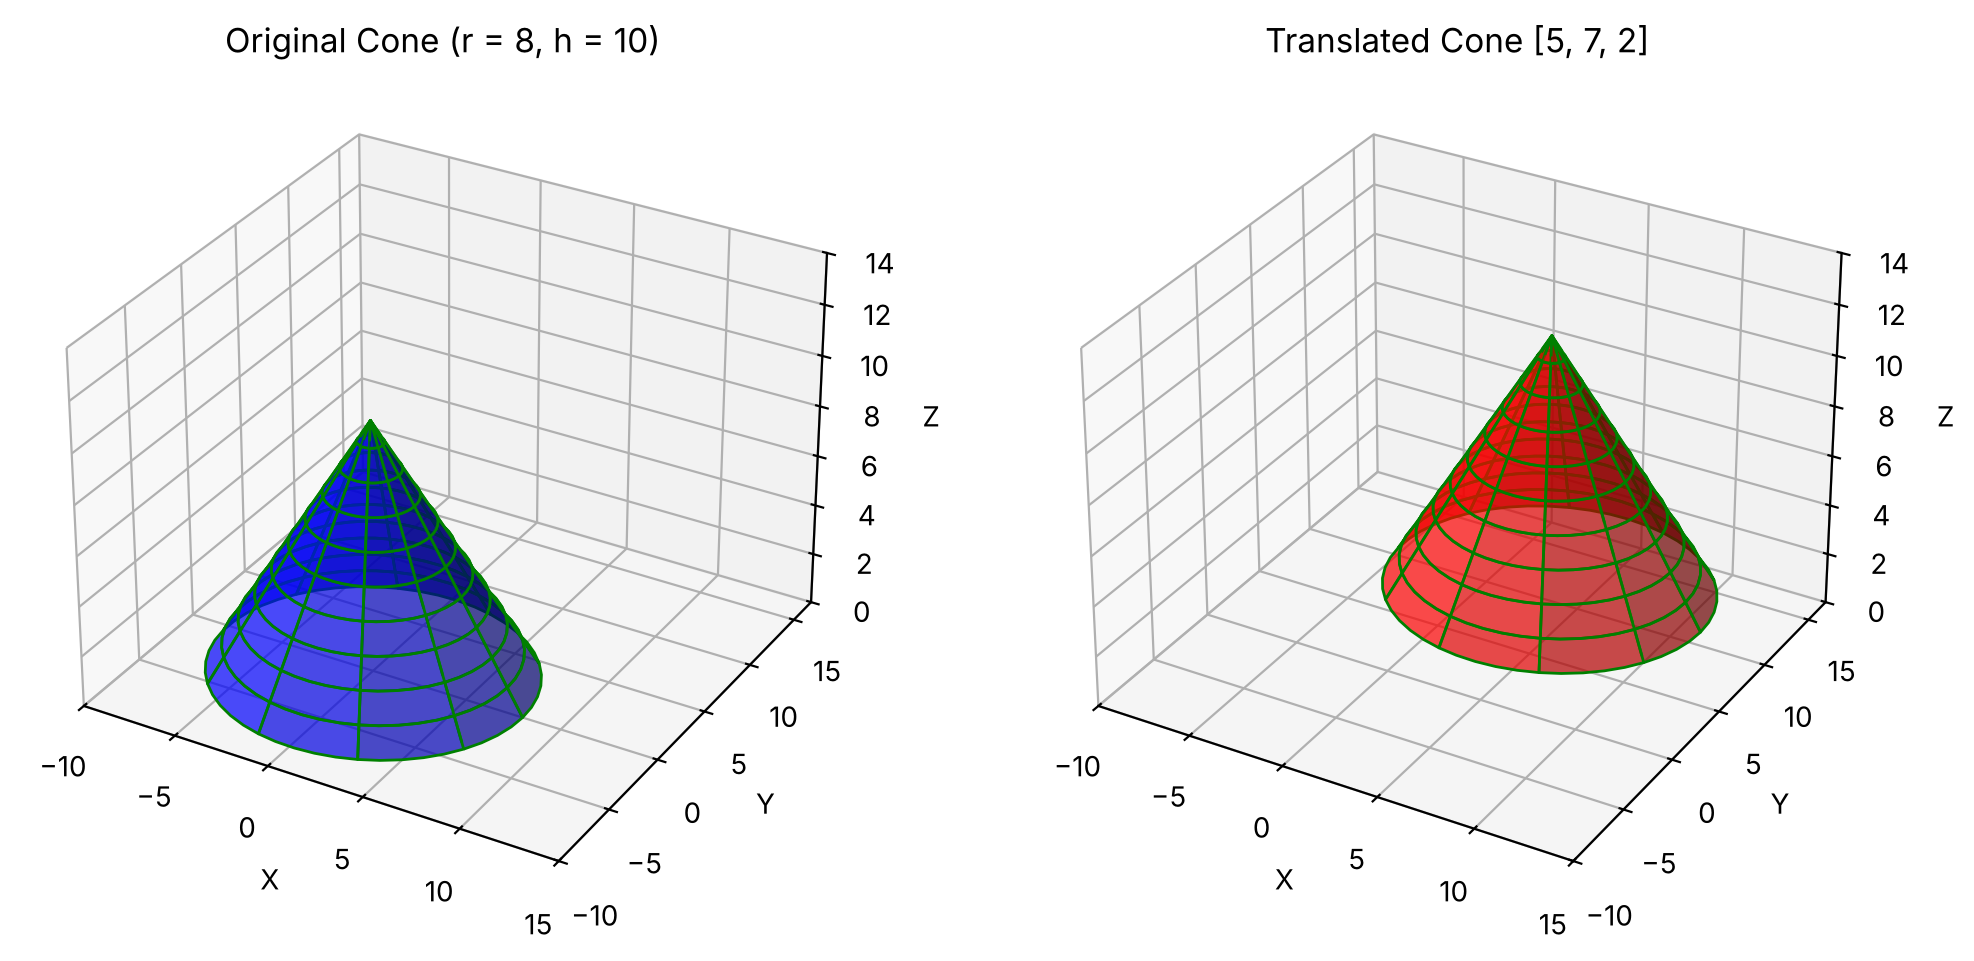

In [5]:
# Plot original and translated cones
fig = plt.figure(figsize=(12, 6))

# Original Cone
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(X, Y, Z, rstride=5, cstride=5, color='blue', edgecolor='green', alpha=0.7)
ax1.set_title('Original Cone (r = 8, h = 10)')
ax1.set_xlabel('X'); ax1.set_ylabel('Y'); ax1.set_zlabel('Z')
ax1.set_xlim([-10, 15])
ax1.set_ylim([-10, 17])
ax1.set_zlim([0, 14])

# Translated Cone
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X_translated, Y_translated, Z_translated, rstride=5, cstride=5,
                 color='red', edgecolor='green', alpha=0.7)
ax2.set_title('Translated Cone [5, 7, 2]')
ax2.set_xlabel('X'); ax2.set_ylabel('Y'); ax2.set_zlabel('Z')
ax2.set_xlim([-10, 15])
ax2.set_ylim([-10, 17])
ax2.set_zlim([0, 14])

plt.show()

In [6]:
#volume of cone
def volume_cone(radius, height):
    return (1/3) * math.pi * radius**2 * height
    #V(cone) = 1/3pi(r^2*h)
    #V = 1/3 * pi * 8^2 * 10 = 670.2064 cubic units

print("Volume of Cone:", volume_cone(radius, height), "cubic units")
# Translation does not change the volume.

Volume of Cone: 670.2064327658225 cubic units


## 2. Rotation of the Cube about the Y-axis

Rotation Matrix (Y axis):
```
| cos(θ)   0  sin(θ)   0 |
|  0       1    0      0 |
| -sin(θ)  0  cos(θ)   0 |
|  0       0    0      1 |
```
where θ = 75°

In [7]:
#DRAWING CUBE
# Define the initial corner and edge length
initial_corner = np.array([3, 6, 4])
edge_length = 5
rotation_angle = np.radians(75)  # Rotation angle in radians (75 degrees)

# Calculate the vertices of the cube
vertices = np.array([
    initial_corner,                                            # (3, 6, 4)
    initial_corner + [edge_length, 0, 0],                      # (3+5, 6, 4)
    initial_corner + [edge_length, edge_length, 0],            # (3+5, 6+5, 4)
    initial_corner + [0, edge_length, 0],                      # (3, 6+5, 4)
    initial_corner + [0, 0, edge_length],                      # (3, 6, 4+5)
    initial_corner + [edge_length, 0, edge_length],            # (3+5, 6, 4+5)
    initial_corner + [edge_length, edge_length, edge_length],  # (3+5, 6+5, 4+5)
    initial_corner + [0, edge_length, edge_length],            # (3, 6+5, 4+5)
])

# Define the faces of the cube using vertex indices
def cube_faces(v):
    return [
        [v[0], v[1], v[2], v[3]],  # Bottom
        [v[4], v[5], v[6], v[7]],  # Top
        [v[0], v[1], v[5], v[4]],  # Front
        [v[2], v[3], v[7], v[6]],  # Back
        [v[1], v[2], v[6], v[5]],  # Right
        [v[4], v[7], v[3], v[0]]   # Left
    ]

faces = cube_faces(vertices)

In [8]:
# Rotation matrix about the Y-axis (homogeneous coordinates)
rotation_matrix = np.array([
    [ np.cos(rotation_angle), 0, np.sin(rotation_angle), 0],
    [ 0,                      1, 0,                      0],
    [-np.sin(rotation_angle), 0, np.cos(rotation_angle), 0],
    [ 0,                      0, 0,                      1]
])
print("Rotation Matrix (Y-axis, 75 degrees):")
print(np.round(rotation_matrix, 4))

# Add the homogeneous coordinate, apply the rotation, and drop it again
points = np.hstack([vertices, np.ones((8, 1))]).T
rotated_vertices = np.dot(rotation_matrix, points)[:3].T

rotated_faces = cube_faces(rotated_vertices)

for i, (old, new) in enumerate(zip(vertices, rotated_vertices), start=1):
    print(f"Corner {i}: {old.tolist()} -> {np.round(new, 4).tolist()}")

Rotation Matrix (Y-axis, 75 degrees):
[[ 0.2588  0.      0.9659  0.    ]
 [ 0.      1.      0.      0.    ]
 [-0.9659  0.      0.2588  0.    ]
 [ 0.      0.      0.      1.    ]]
Corner 1: [3, 6, 4] -> [4.6402, 6.0, -1.8625]
Corner 2: [8, 6, 4] -> [5.9343, 6.0, -6.6921]
Corner 3: [8, 11, 4] -> [5.9343, 11.0, -6.6921]
Corner 4: [3, 11, 4] -> [4.6402, 11.0, -1.8625]
Corner 5: [3, 6, 9] -> [9.4698, 6.0, -0.5684]
Corner 6: [8, 6, 9] -> [10.7639, 6.0, -5.398]
Corner 7: [8, 11, 9] -> [10.7639, 11.0, -5.398]
Corner 8: [3, 11, 9] -> [9.4698, 11.0, -0.5684]


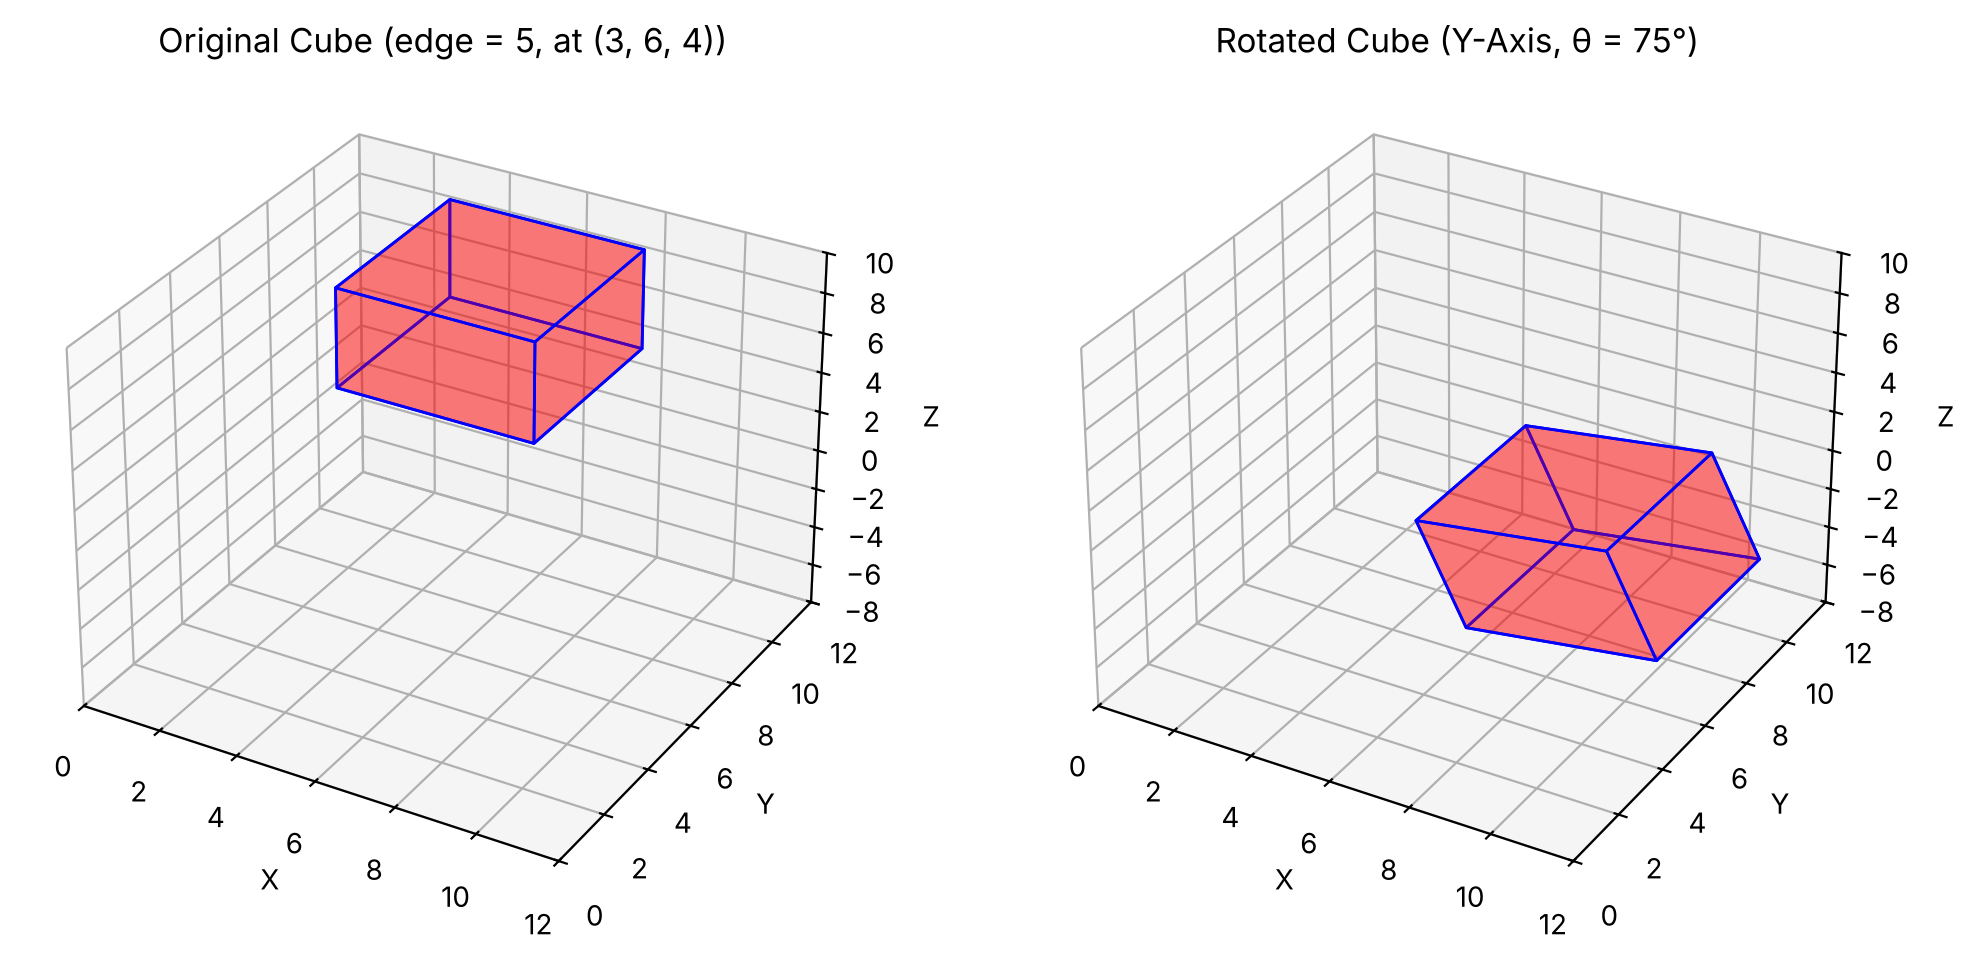

In [9]:
# Plot original and rotated cubes
fig = plt.figure(figsize=(12, 6))

# Original Cube
ax1 = fig.add_subplot(121, projection='3d')
ax1.add_collection3d(Poly3DCollection(faces, facecolors='RED', linewidths=1, edgecolors='BLUE', alpha=.30))
ax1.set_title('Original Cube (edge = 5, at (3, 6, 4))')
ax1.set_xlabel('X'); ax1.set_ylabel('Y'); ax1.set_zlabel('Z')
ax1.set_xlim([0, 12])
ax1.set_ylim([0, 12])
ax1.set_zlim([-8, 10])

# Rotated Cube
ax2 = fig.add_subplot(122, projection='3d')
ax2.add_collection3d(Poly3DCollection(rotated_faces, facecolors='RED', linewidths=1, edgecolors='BLUE', alpha=.30))
ax2.set_title('Rotated Cube (Y-Axis, θ = 75°)')
ax2.set_xlabel('X'); ax2.set_ylabel('Y'); ax2.set_zlabel('Z')
ax2.set_xlim([0, 12])
ax2.set_ylim([0, 12])
ax2.set_zlim([-8, 10])

plt.show()

In [10]:
def volume_cube(side_cube):
    return side_cube**3
# V = 5^3 = 125 cubic units

print("Volume of Cube:", volume_cube(edge_length), 'cubic units')
# Rotation does not change the volume.

Volume of Cube: 125 cubic units
